# Main sweep: structures x balancing modes x 3 seeds

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
DATASETS = json.loads((ROOT / "configs" / "chosen_datasets.json").read_text())["main"]
print("datasets:", DATASETS)
RUN = False
if RUN:
    import subprocess
    subprocess.run([sys.executable, "-m", "experiments.sweep", "--phase", "main", "--datasets", *DATASETS, "--workers", "2"])

datasets: ['fact', 'mod']


balance,lb,none,warmup
structure,,,
dense,NaN,0.542,NaN
dense_wide,NaN,0.985,NaN
mita,0.213,0.222,0.214
moa,0.457,0.352,0.405
moe,0.651,0.441,0.471
moh,0.456,0.520,0.430
mom,0.013,0.009,0.009
momha,0.338,0.453,0.420


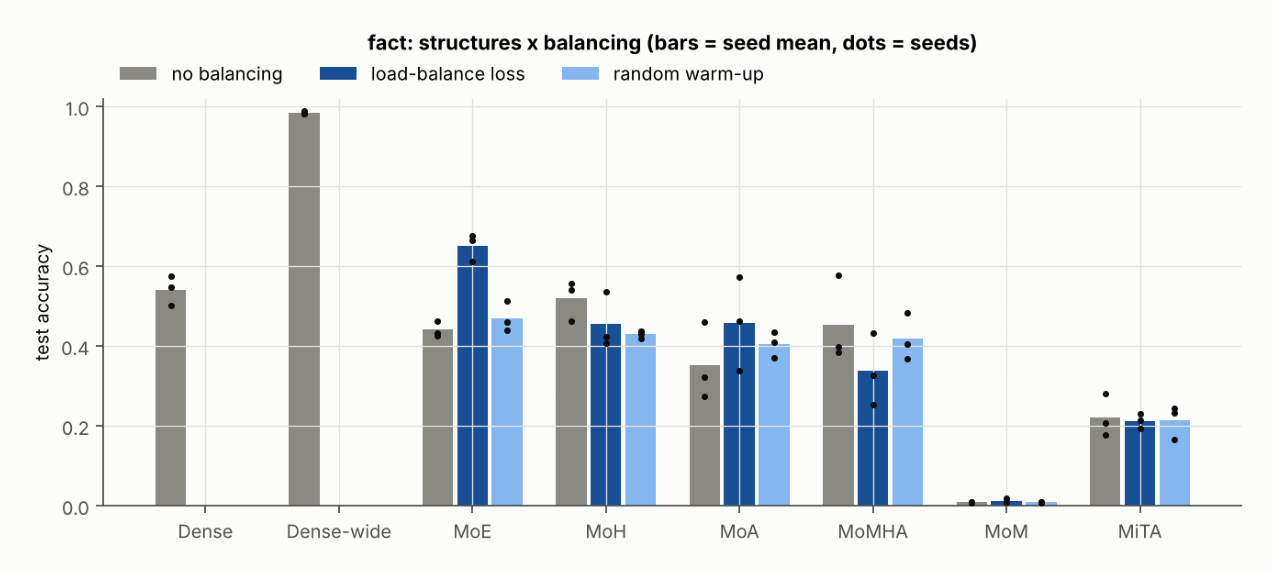

balance,lb,none,warmup
structure,,,
dense,NaN,0.298,NaN
dense_wide,NaN,0.321,NaN
mita,0.213,0.248,0.252
moa,0.168,0.215,0.224
moe,0.280,0.269,0.271
moh,0.280,0.281,0.245
mom,0.015,0.014,0.014
momha,0.242,0.241,0.111


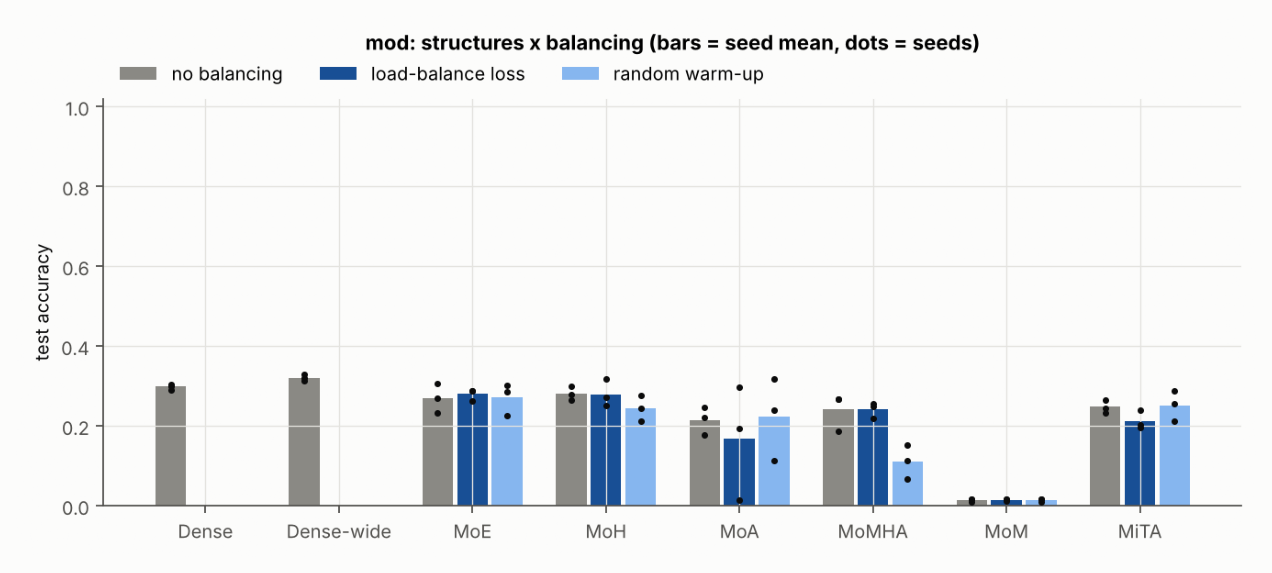

In [3]:
from analysis.collect import load_results, load_history, load_routing, agg, paired_delta
from analysis.routing import collapse_table
from analysis import figures as F
import matplotlib.pyplot as plt, matplotlib.image as mpimg
def show(p):
    if p: plt.figure(figsize=(10, 5)); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()
df = load_results(RUNS_ROOT); main = df[df.variant == "default"]
for d in DATASETS:
    t = agg(main[main.dataset == d], ["structure", "balance"])
    display(t.pivot(index="structure", columns="balance", values="mean").round(3))
    show(F.main_bars(df, d))

,dataset,structure,variant,mean,std,count,comparison
8,fact,dense,default,NaN,NaN,0,lb - none
9,fact,dense_wide,default,NaN,NaN,0,lb - none
10,fact,mita,default,-0.009,0.051,3,lb - none
15,fact,moa,default,0.105,0.167,3,lb - none
18,fact,moe,default,0.210,0.031,3,lb - none
21,fact,moh,default,-0.065,0.060,3,lb - none
24,fact,mom,default,0.004,0.007,3,lb - none
28,fact,momha,default,-0.115,0.051,3,lb - none
8,fact,dense,default,NaN,NaN,0,warmup - none
9,fact,dense_wide,default,NaN,NaN,0,warmup - none


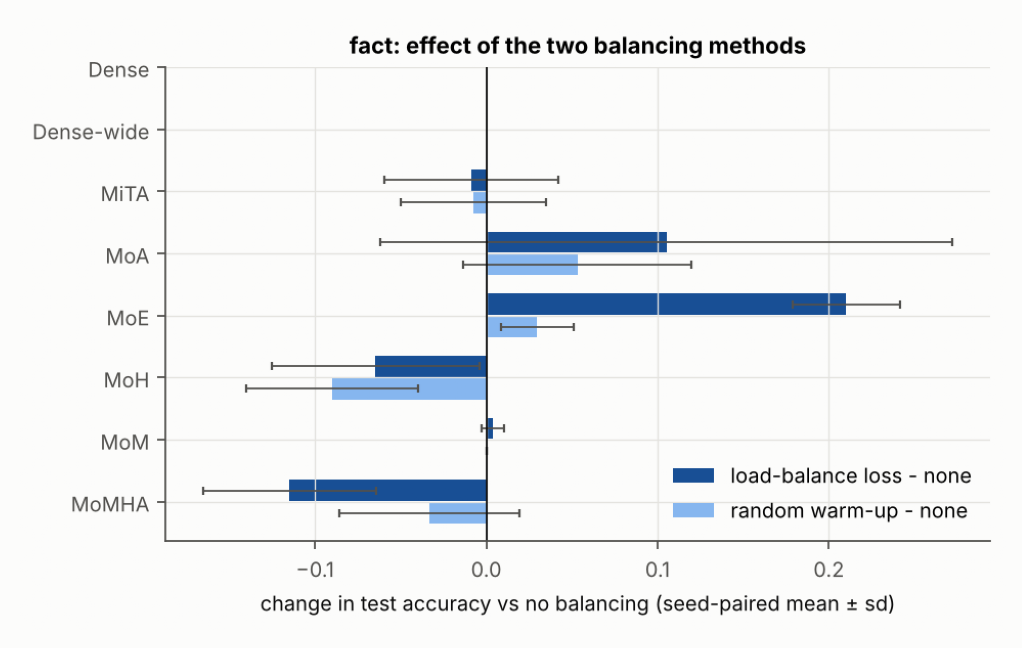

,dataset,structure,variant,mean,std,count,comparison
46,mod,dense,default,NaN,NaN,0,lb - none
47,mod,dense_wide,default,NaN,NaN,0,lb - none
48,mod,mita,default,-0.035,0.009,3,lb - none
49,mod,moa,default,-0.048,0.177,3,lb - none
50,mod,moe,default,0.011,0.024,3,lb - none
51,mod,moh,default,-0.001,0.017,3,lb - none
52,mod,mom,default,0.001,0.005,3,lb - none
53,mod,momha,default,0.001,0.060,3,lb - none
46,mod,dense,default,NaN,NaN,0,warmup - none
47,mod,dense_wide,default,NaN,NaN,0,warmup - none


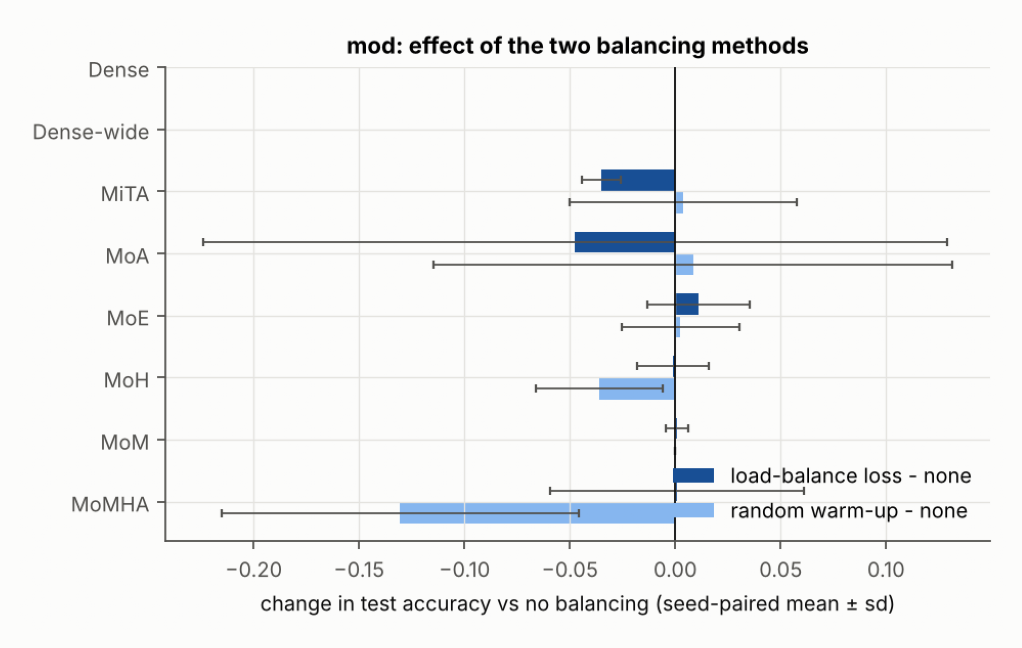

In [4]:
deltas = pd.concat([paired_delta(df, "lb", "none"), paired_delta(df, "warmup", "none")])
for d in DATASETS:
    display(deltas[(deltas.dataset == d) & (deltas.variant == "default")].round(3))
    show(F.balance_delta(deltas[deltas.variant == "default"], d))

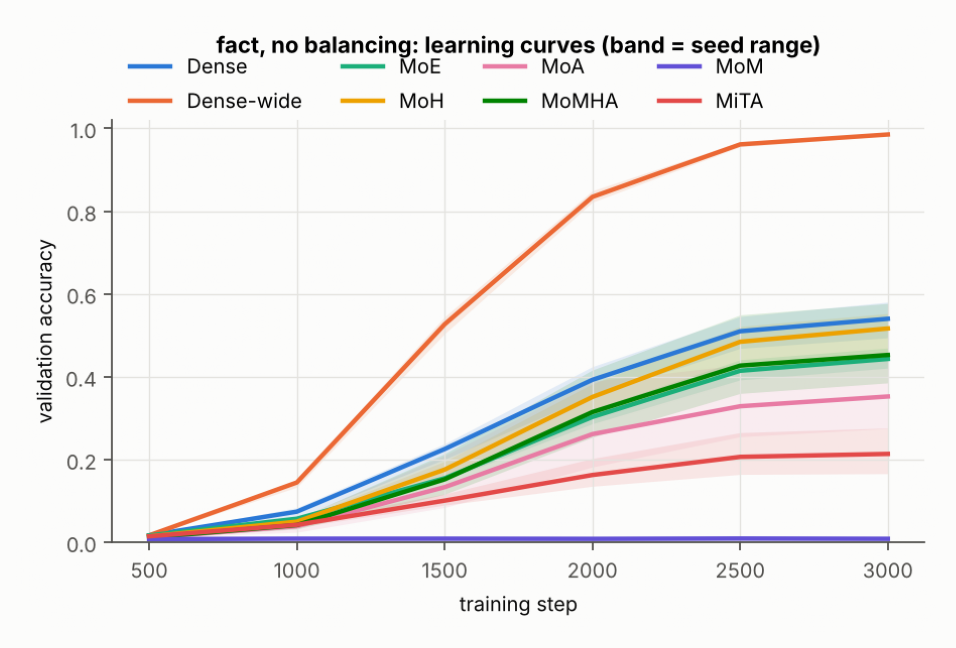

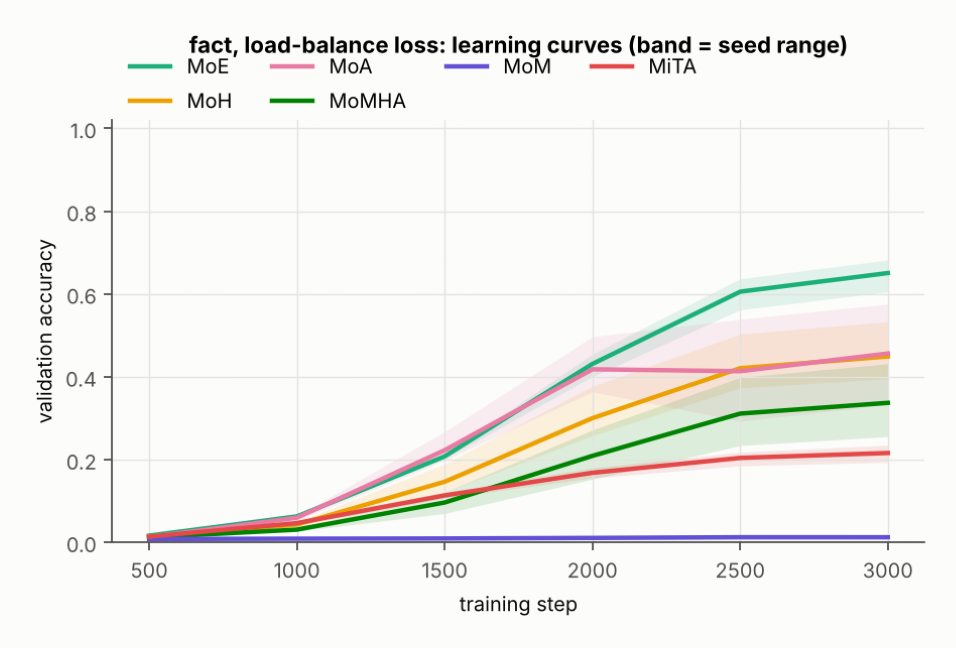

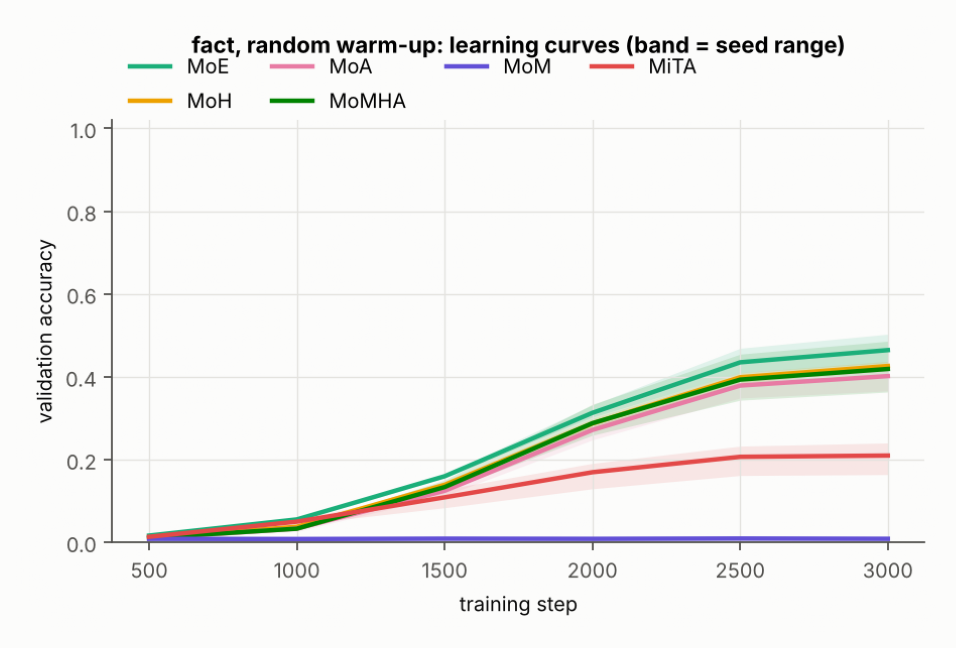

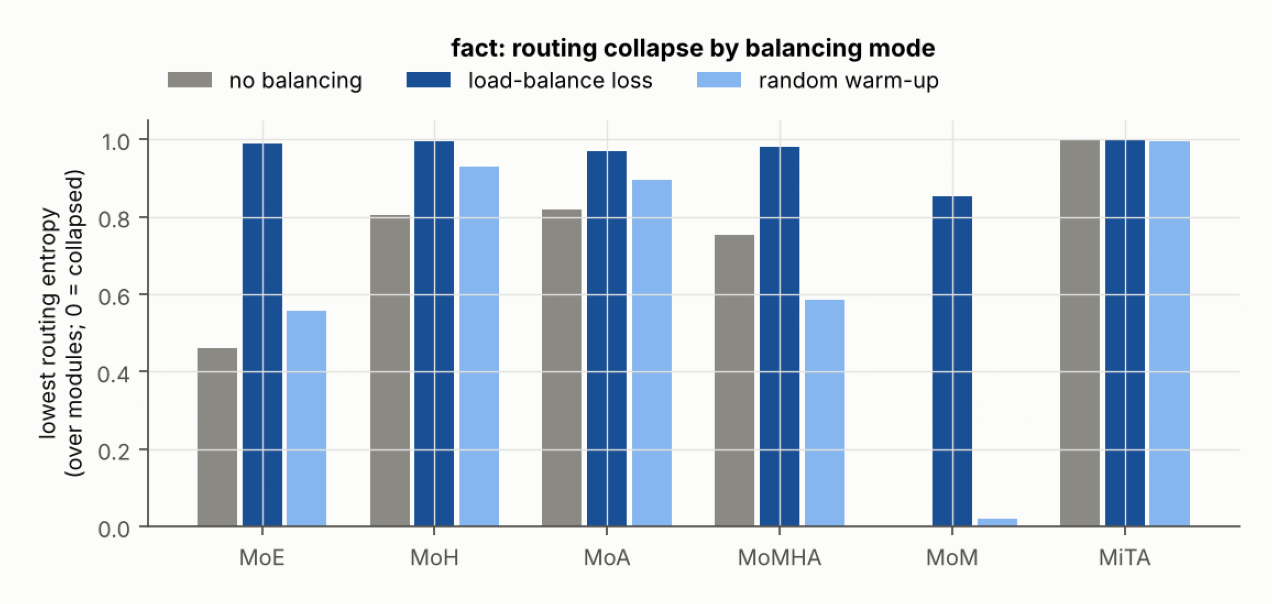

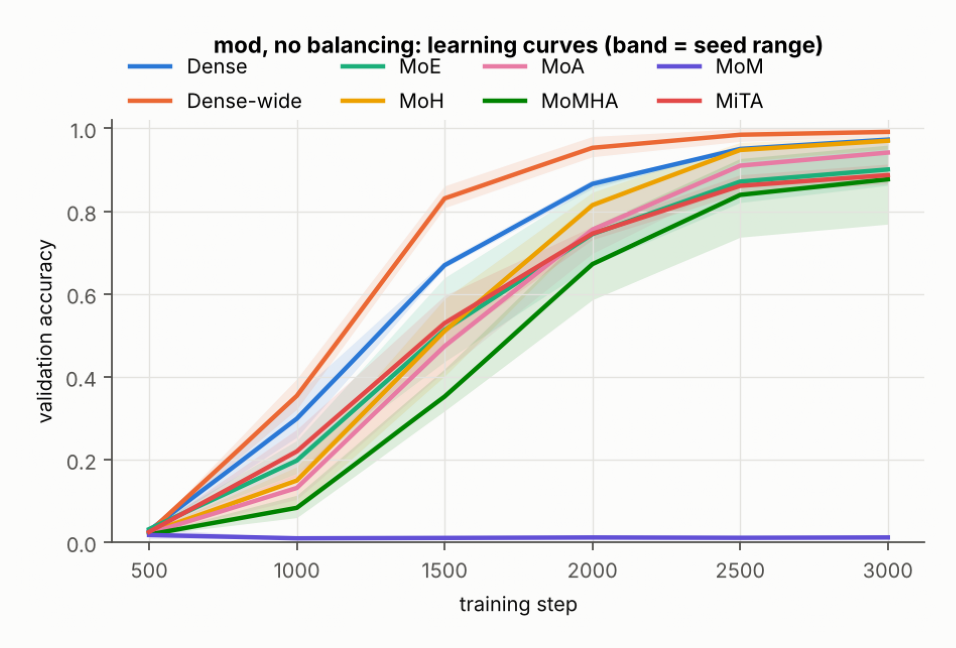

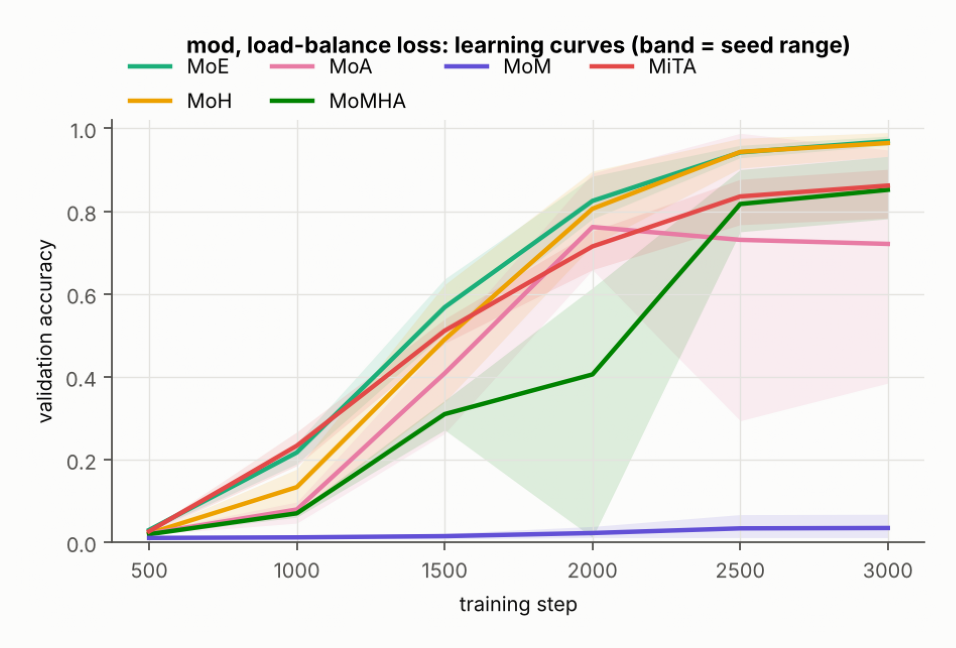

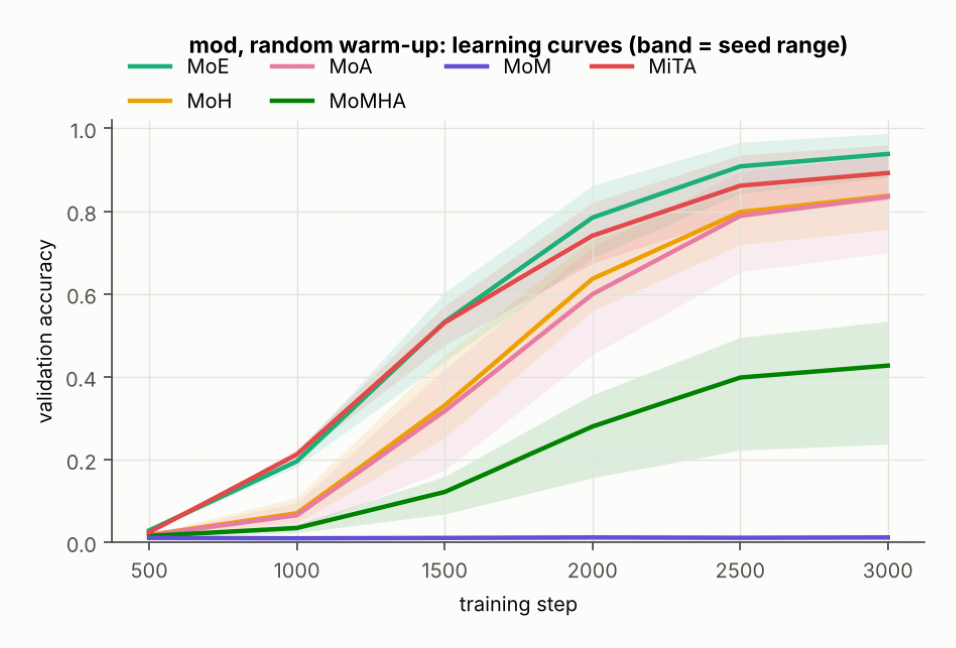

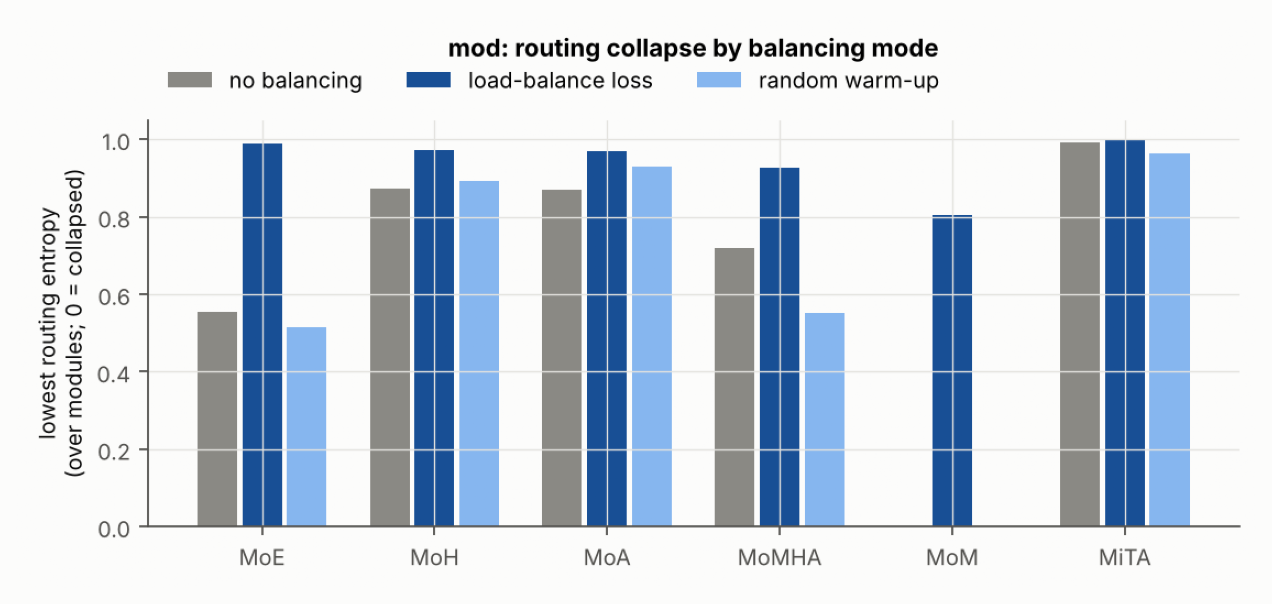

In [5]:
hist = load_history(RUNS_ROOT); rdf = load_routing(RUNS_ROOT); ct = collapse_table(rdf)
for d in DATASETS:
    for b in ["none", "lb", "warmup"]:
        show(F.curves(hist, d, b))
    show(F.collapse_overview(ct, d))